In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
labeled = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_on_off_simple.csv")

Build feature set (per 3s window)

In [7]:
def extract_features(df, win_size=3.0, time_col="TIME"):
    """
    Aggregate features into ~3s windows, grouped by participant, task, and label (ON/OFF).
    """
    feats = []
    gkeys = ["Video Name (folder)", "User ID (file)", "Task Id", "type", "label"]

    for (vn, uid, tid, ttype, lab), grp in df.groupby(gkeys):
        if grp.empty: 
            continue

        # Split into ~3s chunks
        t_min, t_max = grp[time_col].min(), grp[time_col].max()
        bins = np.arange(t_min, t_max+win_size, win_size)

        grp["window"] = pd.cut(grp[time_col], bins=bins, labels=False)

        for w, wgrp in grp.groupby("window"):
            if wgrp.empty: continue

            feats.append({
                "Video Name (folder)": vn,
                "User ID (file)": uid,
                "Task Id": tid,
                "type": ttype,
                "label": lab,
                "window": int(w),

                # Fixation metrics
                "fixation_count": wgrp["FPOGID"].nunique(),
                "mean_fix_dur": wgrp["FPOGD"].mean(),

                # AOI ratio
                "aoi_ratio": (wgrp["AOI"].notna().sum()) / len(wgrp),

                # Pupil metrics
                "mean_pupil_L": wgrp["LPMM"].mean(),
                "mean_pupil_R": wgrp["RPMM"].mean(),
                "var_pupil_L": wgrp["LPMM"].var(),
                "var_pupil_R": wgrp["RPMM"].var(),

                # Saccade metrics
                "mean_saccade_mag": wgrp["SACCADE_MAG"].mean(),
                "var_saccade_dir": wgrp["SACCADE_DIR"].var(),

                # Blink proxy
                "invalid_samples": (wgrp["FPOGV"]==0).sum()
            })
    return pd.DataFrame(feats)

features = extract_features(labeled)  # your labeled df
features.to_csv("outputs/features_windows.csv", index=False)

 on - off differences per feature set


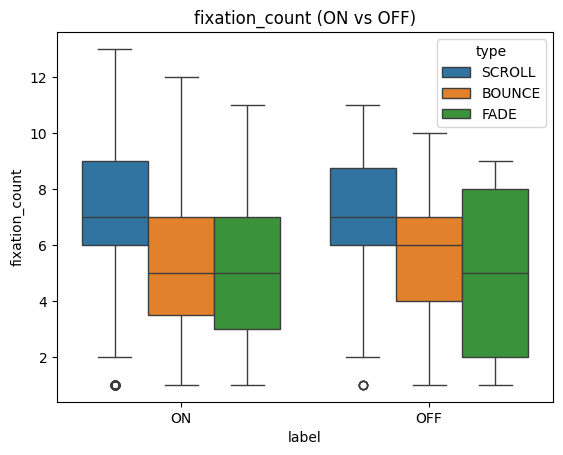

BOUNCE – fixation_count: not enough data for paired test
FADE – fixation_count: not enough data for paired test
SCROLL – fixation_count: not enough data for paired test


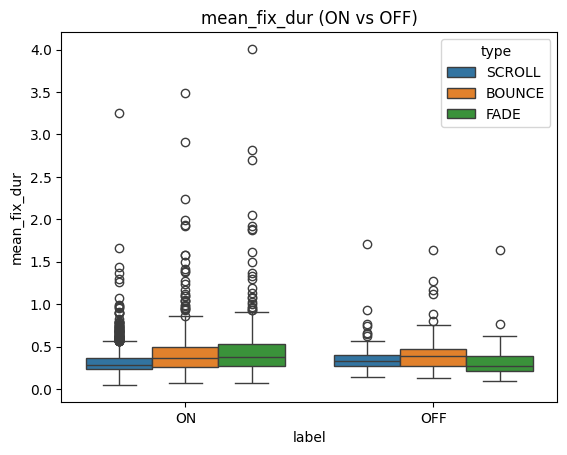

BOUNCE – mean_fix_dur: not enough data for paired test
FADE – mean_fix_dur: not enough data for paired test
SCROLL – mean_fix_dur: not enough data for paired test


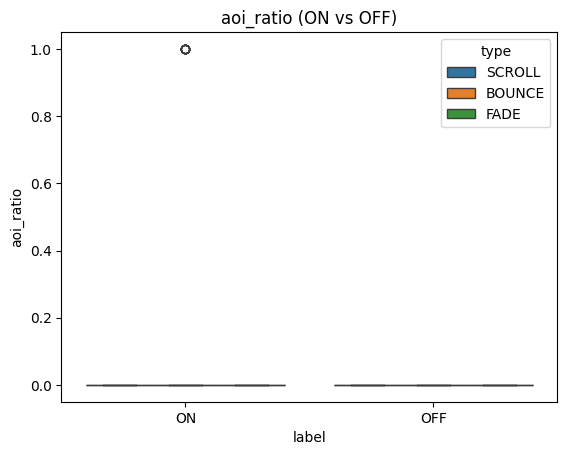

BOUNCE – aoi_ratio: not enough data for paired test
FADE – aoi_ratio: not enough data for paired test
SCROLL – aoi_ratio: not enough data for paired test


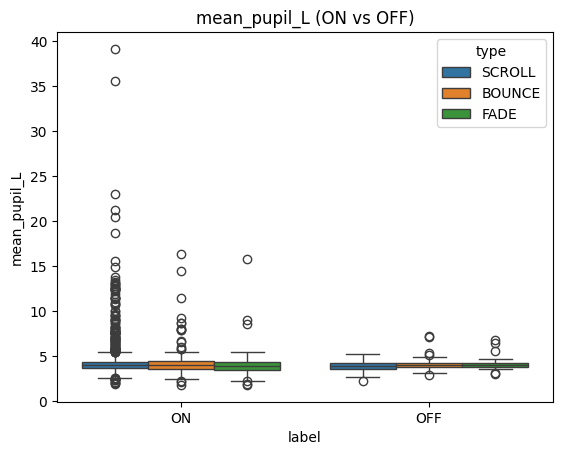

BOUNCE – mean_pupil_L: not enough data for paired test
FADE – mean_pupil_L: not enough data for paired test
SCROLL – mean_pupil_L: not enough data for paired test


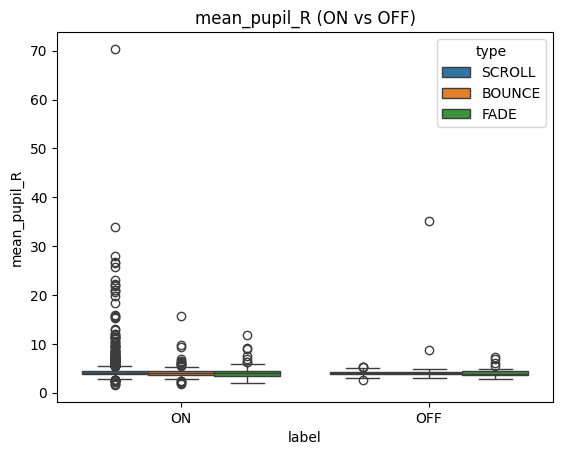

BOUNCE – mean_pupil_R: not enough data for paired test
FADE – mean_pupil_R: not enough data for paired test
SCROLL – mean_pupil_R: not enough data for paired test


In [ ]:
for f in ["fixation_count","mean_fix_dur","aoi_ratio","mean_pupil_L","mean_pupil_R"]:
    sns.boxplot(x="label", y=f, hue="type", data=features)
    plt.title(f"{f} (ON vs OFF)")
    plt.show()

    for ttype, grp in features.groupby("type"):
        on  = grp[grp["label"]=="ON"][f].dropna()
        off = grp[grp["label"]=="OFF"][f].dropna()
        if len(on)>0 and len(off)>0:
            try:
                stat, p = wilcoxon(on, off)
                print(f"{ttype} – {f}: Wilcoxon p={p:.3g}")
            except:
                print(f"{ttype} – {f}: not enough data for paired test")

Baseline-normalized deltas

In [10]:
# For each trial, compute Δ = ON - OFF (per feature)
deltas = []
for (vn, uid, tid, ttype), grp in features.groupby(["Video Name (folder)","User ID (file)","Task Id","type"]):
    f_on  = grp[grp["label"]=="ON"].mean(numeric_only=True)
    f_off = grp[grp["label"]=="OFF"].mean(numeric_only=True)
    if f_on.empty or f_off.empty: continue
    d = (f_on - f_off).to_dict()
    d.update({"Video Name (folder)":vn,"User ID (file)":uid,"Task Id":tid,"type":ttype})
    deltas.append(d)

deltas = pd.DataFrame(deltas)
deltas.to_csv("outputs/deltas.csv", index=False)

PCA

/opt/anaconda3/lib/python3.12/site-packages/sklearn/decomposition/_pca.py:648: RuntimeWarning: invalid value encountered in divide
  explained_variance_ratio_ = explained_variance_ / total_var


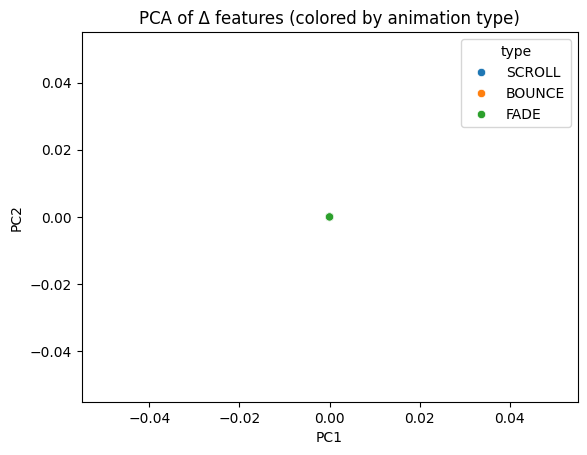

In [11]:
X = deltas.drop(columns=["Video Name (folder)","User ID (file)","Task Id","type"])
X_scaled = StandardScaler().fit_transform(X.fillna(0))

pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
deltas["PC1"] = pcs[:,0]
deltas["PC2"] = pcs[:,1]

sns.scatterplot(x="PC1", y="PC2", hue="type", data=deltas)
plt.title("PCA of Δ features (colored by animation type)")
plt.show()

Clustering

/opt/anaconda3/lib/python3.12/site-packages/sklearn/decomposition/_pca.py:648: RuntimeWarning: invalid value encountered in divide
  explained_variance_ratio_ = explained_variance_ / total_var
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


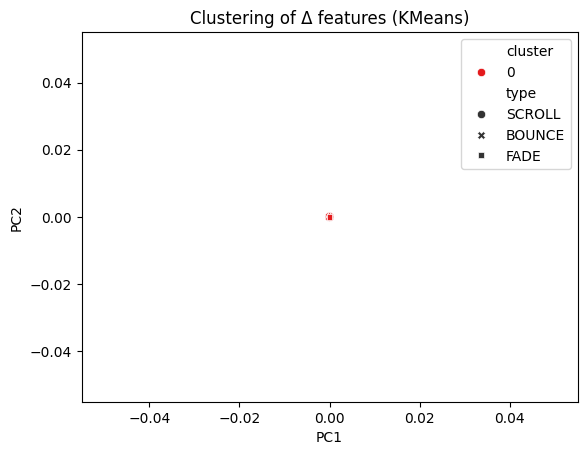

In [13]:
# 1) Prepare data
X = deltas.drop(columns=["Video Name (folder)","User ID (file)","Task Id","type"])
X_scaled = StandardScaler().fit_transform(X.fillna(0))

# 2) Run PCA for visualization
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
deltas["PC1"] = pcs[:,0]
deltas["PC2"] = pcs[:,1]

# 3) Run KMeans clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
deltas["cluster"] = kmeans.fit_predict(X_scaled)

# 4) Visualize clusters
sns.scatterplot(
    x="PC1", y="PC2",
    hue="cluster", style="type",  # color by cluster, marker by task type
    data=deltas, palette="Set1"
)
plt.title("Clustering of Δ features (KMeans)")
plt.show()